# 04 - InceptionV3 Brain Tumor Classification

This notebook trains a deep learning classification model using **InceptionV3** (GoogLeNet family) on brain MRI scans.

### Workflow:
1. **Load Data**: Load train, validation, and test datasets using `image_dataset_from_directory`.
2. **Data Augmentation**: Apply real-time augmentation (random flip, rotation, zoom) to prevent overfitting.
3. **Phase 1 (Feature Extraction)**: Freeze InceptionV3 base, train custom classification head (`learning_rate = 1e-3`).
4. **Phase 2 (Fine-Tuning)**: Unfreeze the top layers of InceptionV3, train with low learning rate (`1e-5`).
5. **Evaluation**: Evaluate on the unseen test set, plot confusion matrix, and compute classification metrics.
6. **Export**: Save the best trained model (`best_model.keras`) and metadata.



In [11]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.metrics import classification_report, confusion_matrix

print(f"TensorFlow version: {tf.__version__}")
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [12]:
%pip install "cryptography>=49,<51"

  Using cached cryptography-50.0.2-cp311-abi3-manylinux_2_34_x86_64.whl.metadata (4.4 kB)
Using cached cryptography-50.0.2-cp311-abi3-manylinux_2_34_x86_64.whl (4.8 MB)
  Attempting uninstall: cryptography
    Found existing installation: cryptography 48.0.1
    Uninstalling cryptography-48.0.1:
      Successfully uninstalled cryptography-48.0.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlflow 3.14.0 requires cryptography<49,>=43.0.0, but you have cryptography 50.0.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [13]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("MLFLOW_TRACKING_PASSWORD")
secret_value_1 = user_secrets.get_secret("MLFLOW_TRACKING_URI")
secret_value_2 = user_secrets.get_secret("MLFLOW_TRACKING_USERNAME")

print(secret_value_0)
print(secret_value_1)
print(secret_value_2)


tS42TaFnk5hDOGM9i6RmeXQI
https://dangerous-tackle-thoroughly-weight.trycloudflare.com
kaggle


In [14]:
# MLflow Setup - connects to  remote tracking server
import subprocess
subprocess.run(["pip", "install", "-q", "mlflow==3.14.0"], check=True)

import os
import mlflow

# Read credentials from Kaggle Secrets (add them in Kaggle > Add-ons > Secrets)
try:
    from kaggle_secrets import UserSecretsClient
    s = UserSecretsClient()
    os.environ["MLFLOW_TRACKING_URI"]      = s.get_secret("MLFLOW_TRACKING_URI")
    os.environ["MLFLOW_TRACKING_USERNAME"] = s.get_secret("MLFLOW_TRACKING_USERNAME")
    os.environ["MLFLOW_TRACKING_PASSWORD"] = s.get_secret("MLFLOW_TRACKING_PASSWORD")
    print("Kaggle Secrets loaded successfully.")
except Exception:
    # Fallback: paste credentials directly (only for quick testing)
    os.environ["MLFLOW_TRACKING_URI"]      = "https://fit-point-mind-turn.trycloudflare.com"
    os.environ["MLFLOW_TRACKING_USERNAME"] = "kaggle"
    os.environ["MLFLOW_TRACKING_PASSWORD"] = "tS42TaFnk5hDOGM9i6RmeXQI"
    print("Using hardcoded credentials (fallback).")

mlflow.set_tracking_uri(os.environ["MLFLOW_TRACKING_URI"])
mlflow.set_experiment("neurovision-inceptionv3")
print(f"MLflow tracking URI: {mlflow.get_tracking_uri()}")


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pyopenssl 26.4.0 requires cryptography<51,>=49.0.0, but you have cryptography 48.0.1 which is incompatible.


Kaggle Secrets loaded successfully.
MLflow tracking URI: https://dangerous-tackle-thoroughly-weight.trycloudflare.com


In [15]:
# Environment and Paths Setup
if Path("/kaggle/input").exists():
    WORK_DIR = Path("/kaggle/working")
    # Auto-locate prepared classification directory inside Kaggle input
    train_candidates = list(Path("/kaggle/input").rglob("train"))
    if train_candidates:
        DATA_DIR = train_candidates[0].parent
    else:
        DATA_DIR = Path("/kaggle/input/neurovision-classification")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR = ROOT / "data" / "prepared" / "classification"
    WORK_DIR = ROOT

MODEL_DIR = WORK_DIR / "models" / "classification"
OUT_DIR = WORK_DIR / "outputs"
METRICS_DIR = OUT_DIR / "metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data Directory:   {DATA_DIR}")
print(f"Model Directory:  {MODEL_DIR}")
print(f"Output Directory: {OUT_DIR}")


Data Directory:   /kaggle/input/datasets/hamzalafsioui/neurovision-classification/classification
Model Directory:  /kaggle/working/models/classification
Output Directory: /kaggle/working/outputs


In [16]:
# Hyperparameters & Configuration
IMG_SIZE = (299, 299)   # InceptionV3 standard input size
BATCH_SIZE = 32         # Adjust to 16 if memory is constrained
SEED = 42

EPOCHS_PHASE1 = 10      # Feature extraction epochs
EPOCHS_PHASE2 = 10      # Fine-tuning epochs
LR_PHASE1 = 1e-3
LR_PHASE2 = 1e-5

CLASSES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
NUM_CLASSES = len(CLASSES)


In [18]:
# Load Datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="categorical"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="categorical"
)

class_names = train_ds.class_names
print(f"Classes detected: {class_names}")

# Normalize pixels using InceptionV3 preprocess_input (-1 to 1)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)


Found 4025 files belonging to 4 classes.
Found 512 files belonging to 4 classes.
Found 712 files belonging to 4 classes.
Classes detected: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [19]:
# Build Model with Data Augmentation (InceptionV3 Base + Custom Head)

# Simple data augmentation pipeline (active during training only)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

base_model = InceptionV3(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

# Freeze the base model for Phase 1
base_model.trainable = False

# Build complete model
inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="input_image")
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="avg_pool")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = models.Model(inputs=inputs, outputs=outputs, name="InceptionV3_BrainTumor")

model.compile(
    optimizer=optimizers.Adam(learning_rate=LR_PHASE1),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(f"Total parameters:     {model.count_params():,}")
print(f"Trainable parameters: {sum(tf.size(w).numpy() for w in model.trainable_weights):,}")


87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters:     21,810,980
Trainable parameters: 8,196


In [20]:
# Phase 1: Feature Extraction Training
print("=== Starting Phase 1: Feature Extraction ===")

best_model_path = MODEL_DIR / "best_model.keras"

cb_phase1 = [
    callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

history_fe = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=cb_phase1
)


=== Starting Phase 1: Feature Extraction ===
Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 661ms/step - accuracy: 0.5262 - loss: 1.0655
Epoch 1: val_accuracy improved from None to 0.78906, saving model to /kaggle/working/models/classification/best_model.keras

Epoch 1: finished saving model to /kaggle/working/models/classification/best_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 110s 775ms/step - accuracy: 0.6524 - loss: 0.8300 - val_accuracy: 0.7891 - val_loss: 0.6218
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.7939 - loss: 0.5613
Epoch 2: val_accuracy improved from 0.78906 to 0.81836, saving model to /kaggle/working/models/classification/best_model.keras

Epoch 2: finished saving model to /kaggle/working/models/classification/best_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 22s 171ms/step - accuracy: 0.8030 - loss: 0.5372 - val_accuracy: 0.8184 - val_loss: 0.5332
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step - accuracy: 0.8266 - loss: 0.4793
Epoch 3: val_accura

In [21]:
# Phase 2: Fine-Tuning Top Layers
print("=== Starting Phase 2: Fine-Tuning ===")

# Unfreeze base model and freeze early layers (keep layers before index 249 frozen)
base_model.trainable = True
for layer in base_model.layers[:249]:
    layer.trainable = False

trainable_count = sum(tf.size(w).numpy() for w in model.trainable_weights)
print(f"Trainable parameters in Fine-Tuning: {trainable_count:,}")

model.compile(
    optimizer=optimizers.Adam(learning_rate=LR_PHASE2),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cb_phase2 = [
    callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE2,
    callbacks=cb_phase2
)


=== Starting Phase 2: Fine-Tuning ===
Trainable parameters in Fine-Tuning: 11,123,076
Epoch 1/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.5807 - loss: 1.1103
Epoch 1: val_accuracy improved from None to 0.85742, saving model to /kaggle/working/models/classification/best_model.keras

Epoch 1: finished saving model to /kaggle/working/models/classification/best_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 48s 273ms/step - accuracy: 0.7039 - loss: 0.7919 - val_accuracy: 0.8574 - val_loss: 0.3697
Epoch 2/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.8575 - loss: 0.4109
Epoch 2: val_accuracy improved from 0.85742 to 0.90625, saving model to /kaggle/working/models/classification/best_model.keras

Epoch 2: finished saving model to /kaggle/working/models/classification/best_model.keras
126/126 ━━━━━━━━━━━━━━━━━━━━ 35s 274ms/step - accuracy: 0.8661 - loss: 0.3877 - val_accuracy: 0.9062 - val_loss: 0.2828
Epoch 3/10
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0

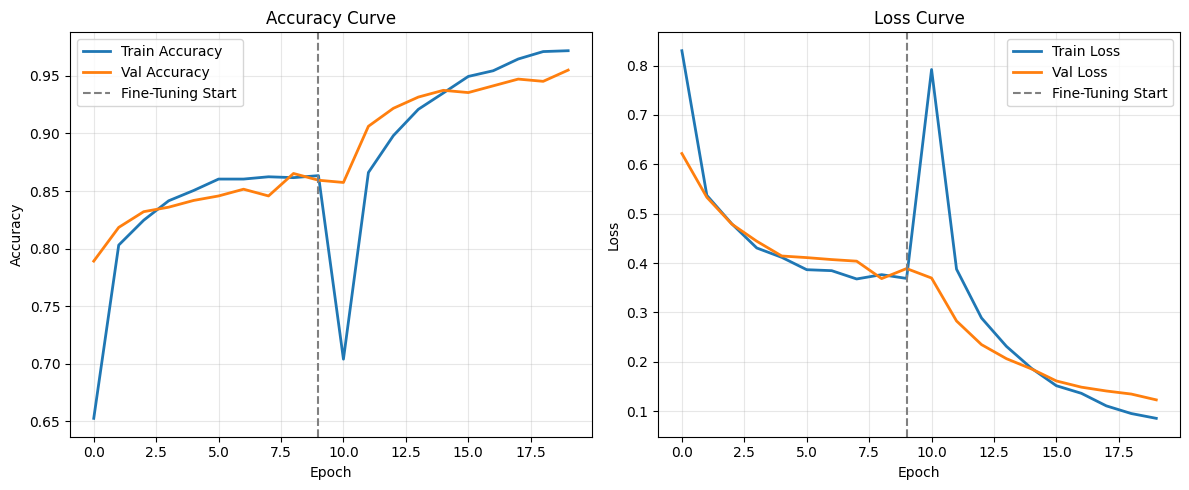

In [22]:
# Plot Training Curves
acc = history_fe.history['accuracy'] + history_ft.history['accuracy']
val_acc = history_fe.history['val_accuracy'] + history_ft.history['val_accuracy']
loss = history_fe.history['loss'] + history_ft.history['loss']
val_loss = history_fe.history['val_loss'] + history_ft.history['val_loss']

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(acc, label="Train Accuracy", lw=2)
plt.plot(val_acc, label="Val Accuracy", lw=2)
plt.axvline(x=len(history_fe.history['accuracy'])-1, color='gray', linestyle='--', label='Fine-Tuning Start')
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train Loss", lw=2)
plt.plot(val_loss, label="Val Loss", lw=2)
plt.axvline(x=len(history_fe.history['loss'])-1, color='gray', linestyle='--', label='Fine-Tuning Start')
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUT_DIR / "classification_training_curves.png", dpi=120)
plt.show()


=== Evaluating on Test Set ===
23/23 ━━━━━━━━━━━━━━━━━━━━ 26s 922ms/step - accuracy: 0.9635 - loss: 0.1039

Test Accuracy: 0.9635 (96.35%)
Test Loss:     0.1039

--- Classification Report ---
              precision    recall  f1-score   support

      Glioma     0.9593    0.9538    0.9565       173
  Meningioma     0.9535    0.9404    0.9469       218
    No Tumor     0.9904    0.9626    0.9763       107
   Pituitary     0.9638    0.9953    0.9793       214

    accuracy                         0.9635       712
   macro avg     0.9667    0.9630    0.9648       712
weighted avg     0.9635    0.9635    0.9634       712



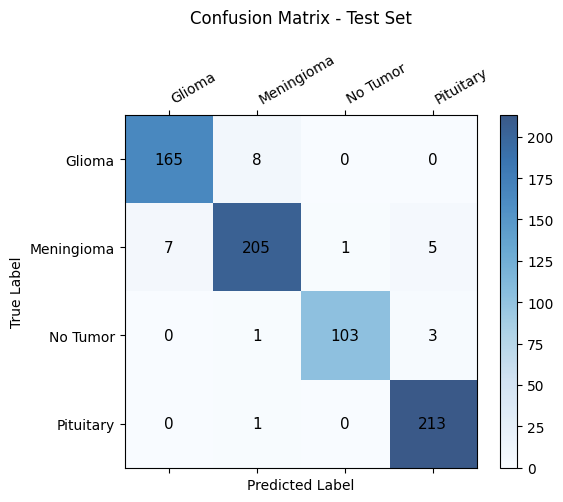

In [23]:
# Evaluate on Test Dataset
print("=== Evaluating on Test Set ===")

# Load best saved checkpoint
best_model = tf.keras.models.load_model(str(best_model_path))

test_loss, test_acc = best_model.evaluate(test_ds, verbose=1)
print(f"\nTest Accuracy: {test_acc:.4f} ({test_acc * 100:.2f}%)")
print(f"Test Loss:     {test_loss:.4f}")

# Collect predictions and true labels
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Print classification report
report_text = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print("\n--- Classification Report ---")
print(report_text)

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.matshow(cm, cmap="Blues", alpha=0.8)
fig.colorbar(cax)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color="black", fontsize=11)

ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=30, ha="left")
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix - Test Set", pad=20)
plt.tight_layout()
plt.savefig(METRICS_DIR / "confusion_matrix.png", dpi=120)
plt.show()


In [25]:
# Save Metadata & Outputs
# Duplicate best_model.keras as best_inceptionv3.keras for compatibility
import shutil
shutil.copy2(best_model_path, MODEL_DIR / "best_inceptionv3.keras")

# Save class names JSON
class_dict = {i: name for i, name in enumerate(class_names)}
with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(class_dict, f, indent=2)

# Save metrics summary JSON
metrics_summary = {
    "model": "InceptionV3",
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "num_classes": len(class_names),
    "classes": class_names
}

with open(METRICS_DIR / "test_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2)

print("=== Training Complete ===")
print(f"Best Model:      {best_model_path}")
print(f"Class Mapping:   {MODEL_DIR / 'class_names.json'}")
print(f"Metrics Summary: {METRICS_DIR / 'test_metrics.json'}")


=== Training Complete ===
Best Model:      /kaggle/working/models/classification/best_model.keras
Class Mapping:   /kaggle/working/models/classification/class_names.json
Metrics Summary: /kaggle/working/outputs/metrics/test_metrics.json


In [26]:
# Log training results to MLflow
with mlflow.start_run(run_name="inceptionv3-brain-tumor"):

    # Log hyperparameters
    mlflow.log_params({
        "model":           "InceptionV3",
        "img_size":        str(IMG_SIZE),
        "batch_size":      BATCH_SIZE,
        "epochs_phase1":   EPOCHS_PHASE1,
        "epochs_phase2":   EPOCHS_PHASE2,
        "lr_phase1":       LR_PHASE1,
        "lr_phase2":       LR_PHASE2,
        "num_classes":     NUM_CLASSES,
        "classes":         str(class_names),
        "augmentation":    "RandomFlip, RandomRotation(0.1), RandomZoom(0.1)",
        "dropout":         0.3,
        "fine_tune_from":  249,
    })

    # Log epoch-by-epoch metrics for Phase 1
    for epoch, (acc, val_acc, loss, val_loss) in enumerate(zip(
        history_fe.history["accuracy"],
        history_fe.history["val_accuracy"],
        history_fe.history["loss"],
        history_fe.history["val_loss"]
    )):
        mlflow.log_metrics({
            "fe_train_accuracy": acc,
            "fe_val_accuracy":   val_acc,
            "fe_train_loss":     loss,
            "fe_val_loss":       val_loss,
        }, step=epoch)

    # Log epoch-by-epoch metrics for Phase 2
    for epoch, (acc, val_acc, loss, val_loss) in enumerate(zip(
        history_ft.history["accuracy"],
        history_ft.history["val_accuracy"],
        history_ft.history["loss"],
        history_ft.history["val_loss"]
    )):
        mlflow.log_metrics({
            "ft_train_accuracy": acc,
            "ft_val_accuracy":   val_acc,
            "ft_train_loss":     loss,
            "ft_val_loss":       val_loss,
        }, step=epoch)

    # Log final test metrics
    mlflow.log_metrics({
        "test_accuracy": float(test_acc),
        "test_loss":     float(test_loss),
    })

    # Log output files as artifacts
    mlflow.log_artifact(str(METRICS_DIR / "confusion_matrix.png"))
    mlflow.log_artifact(str(METRICS_DIR / "test_metrics.json"))
    mlflow.log_artifact(str(OUT_DIR / "classification_training_curves.png"))
    mlflow.log_artifact(str(MODEL_DIR / "class_names.json"))

    print("All metrics and artifacts logged to MLflow!")
    print(f"Run URL: {mlflow.get_tracking_uri()}")


All metrics and artifacts logged to MLflow!
Run URL: https://dangerous-tackle-thoroughly-weight.trycloudflare.com
🏃 View run inceptionv3-brain-tumor at: https://dangerous-tackle-thoroughly-weight.trycloudflare.com/#/experiments/2/runs/4b53e12c198b4060a6ad1e63e6a37028
🧪 View experiment at: https://dangerous-tackle-thoroughly-weight.trycloudflare.com/#/experiments/2
